# 01 - Exploratory Data Analysis

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning
**Dataset:** PhiUSIIL Phishing URL Dataset (UCI Machine Learning Repository, 2024)
**Objective:** Understand the structure, quality and class balance of the dataset before preprocessing.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Rows: 235,795 | Columns: 56


## 1. Dataset Overview

In [3]:
df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  str    
 1   URL                         235795 non-null  str    
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  str    
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  str    
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation           

In [6]:
text_cols = df.select_dtypes(include="str").columns.tolist()
print(f"Text columns ({len(text_cols)}): {text_cols}")

Text columns (5): ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']


## 2. Data Quality Check

In [7]:
missing = df.isnull().sum()
print(f"Total missing values: {missing.sum()}")
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

In [8]:
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates}")

Duplicate rows: 0


In [9]:
duplicate_urls = df["URL"].duplicated().sum()
print(f"Duplicate URLs: {duplicate_urls}")

Duplicate URLs: 425


In [10]:
dup_mask = df["URL"].duplicated(keep=False)
dup_df = df[dup_mask]
label_conflicts = dup_df.groupby("URL")["label"].nunique()

print(f"Rows involved in duplication: {dup_mask.sum()}")
print(f"Unique duplicated URLs: {dup_df['URL'].nunique()}")
print(f"URLs with conflicting labels: {(label_conflicts > 1).sum()}")

Rows involved in duplication: 850
Unique duplicated URLs: 425
URLs with conflicting labels: 0


### Findings: Data Quality

- The dataset contains **235,795 rows** and **56 columns**, with **no missing values**.
- Five columns are text-based (`FILENAME`, `URL`, `Domain`, `TLD`, `Title`) and are not directly usable by ML models.
- No fully duplicated rows were found, because the `FILENAME` column is unique for every record.
- However, **425 URLs appear twice** (850 rows in total). All duplicated URLs have the **same label**, so there are no conflicting records.
- These duplicates will be removed during preprocessing to prevent the same URL from appearing in both the training and test sets.

## 3. Class Distribution

In [11]:
LABEL_NAMES = {0: "Phishing", 1: "Legitimate"}

class_counts = df["label"].map(LABEL_NAMES).value_counts()
class_pct = (class_counts / len(df) * 100).round(2)
pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct})

,Count,Percentage (%)
label,,
Legitimate,134850,57.19
Phishing,100945,42.81


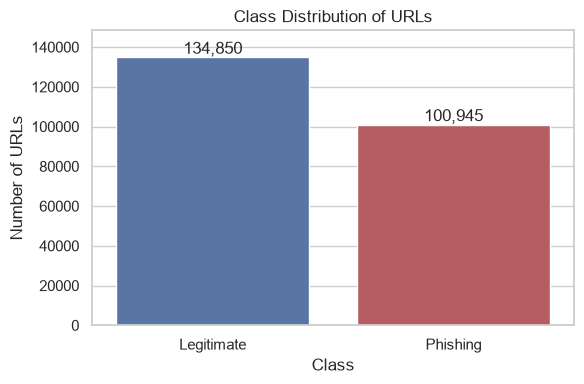

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
class_labels = df["label"].map(LABEL_NAMES)
sns.countplot(x=class_labels, hue=class_labels, order=["Legitimate", "Phishing"], palette=["#4C72B0", "#C44E52"], legend=False, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

ax.margins(y=0.1)
ax.set_title("Class Distribution of URLs")
ax.set_xlabel("Class")
ax.set_ylabel("Number of URLs")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "class_distribution.png", dpi=300)
plt.show()

### Findings: Class Distribution

- The dataset contains **134,850 legitimate URLs (57.19%)** and **100,945 phishing URLs (42.81%)**.
- The label encoding is **1 = Legitimate** and **0 = Phishing**.
- The class ratio is approximately **57:43**, so the dataset is **reasonably balanced** and does not require resampling techniques such as SMOTE.
- A **stratified train-test split** will still be used to preserve this ratio in both sets.
- Since a model predicting only "Legitimate" would already achieve ~57% accuracy, models will be evaluated using **Precision, Recall and F1-score** in addition to accuracy.

## 4. Feature Correlation with Target

In [14]:
numeric_df = df.drop(columns=text_cols)
target_corr = numeric_df.corr()["label"].drop("label").sort_values(key=abs, ascending=False)
target_corr.head(15)

URLSimilarityIndex       0.860358
HasSocialNet             0.784255
HasCopyrightInfo         0.743358
HasDescription           0.690232
IsHTTPS                  0.609132
DomainTitleMatchScore    0.584905
HasSubmitButton          0.578561
IsResponsive             0.548608
URLTitleMatchScore       0.539419
SpacialCharRatioInURL   -0.533537
HasHiddenFields          0.507731
HasFavicon               0.493711
URLCharProb              0.469749
CharContinuationRate     0.467735
HasTitle                 0.459725
Name: label, dtype: float64

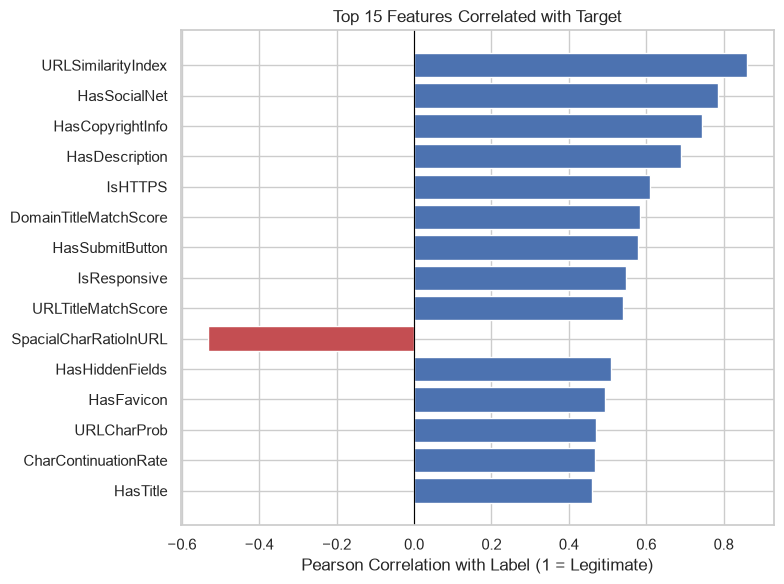

In [15]:
top_corr = target_corr.head(15)
colors = ["#4C72B0" if value > 0 else "#C44E52" for value in top_corr]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 Features Correlated with Target")
ax.set_xlabel("Pearson Correlation with Label (1 = Legitimate)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "feature_correlation.png", dpi=300)
plt.show()

### Findings: Feature Correlation

- **`URLSimilarityIndex`** shows the strongest correlation with the target (**0.86**), making it the most informative single feature.
- Page-content features such as **`HasSocialNet`** (0.78), **`HasCopyrightInfo`** (0.74) and **`HasDescription`** (0.69) are strongly associated with legitimate websites.
- **`IsHTTPS`** (0.61) indicates that legitimate URLs are more likely to use secure HTTPS connections.
- **`SpacialCharRatioInURL`** (-0.53) is the strongest negative feature, meaning URLs with a higher ratio of special characters are more likely to be phishing.
- Several features have very high correlation with the target, so very high model accuracy is expected. Model results will be interpreted with this in mind.